# Experiment 07 — TensorNequIP isotropic shielding

Evaluate **TensorNequIP-NMR-9065266**, using the saved checkpoint selected by validation loss. The primary result is performance on the **150 test structures**. Training and validation results diagnose fitting and generalisation; validation selected the checkpoint and is not an independent test.

The target is the **absolute isotropic magnetic shielding**, $\sigma_\mathrm{iso}=\operatorname{Tr}(\boldsymbol\sigma)/3$, stored as `MS_Iso_QM` in **ppm**. This is a scalar per atomic site. Predictions are compared directly with the CASTEP/PBE reference labels, without fitting any referencing or bias correction to the evaluation data. This notebook does not measure agreement with experimental chemical shifts or predict tensor anisotropy.

**Evaluation protocol.** Report Si and O separately: RMSE, MAE and $R^2$, plus signed bias, tail errors, parity plots and residual distributions. Use a training-only elemental-mean predictor as a baseline. Pooling Si and O into one $R^2$ would be misleading because their different average shieldings dominate the apparent correlation.

**Literature basis:** [ShiftML2, Fig. 2 and Table 1](https://pmc.ncbi.nlm.nih.gov/articles/PMC9549463/) uses shielding parity plots, error distributions, RMSE, MAE and $R^2$ against DFT. [Machine Learning Full NMR Chemical Shift Tensors of Silicon Oxides with Equivariant Graph Neural Networks](https://pmc.ncbi.nlm.nih.gov/articles/PMC10026072/) reports MAE for silicon NMR targets including isotropic shifts. These motivate the reporting format, not a numerical head-to-head benchmark: their datasets and targets differ from ours.

Run all cells with this project's `.venv` Python kernel, from the project root or `experiments/`. The notebook reads the existing model/data and writes no project files. Full CPU inference takes several minutes. All indices below are zero-based.


In [1]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from graph_pes.utils.nn import count_used_parameters
from IPython.display import display, Markdown

RUN_NAME = 'TensorNequIP-NMR-9065266'
candidates = ([Path(os.environ['NEQUIP_PROJECT'])] if 'NEQUIP_PROJECT' in os.environ else [])
candidates += [Path.cwd(), *Path.cwd().parents,
               Path('/Users/louismcauliffe/code/research/NequIP_experiments')]
PROJECT = next((p.resolve() for p in candidates
                if (p / 'graph-pes-results' / RUN_NAME / 'model.pt').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Set NEQUIP_PROJECT to the NequIP_experiments directory.')
sys.path.insert(0, str(PROJECT))
# Required to unpickle the trusted local model; importing does not generate data.
import nmr_helpers

RUN = PROJECT / 'graph-pes-results' / RUN_NAME
SPLITS = ['train', 'valid', 'test']
ELEMENTS = ['Si', 'O']
COLOURS = {'Si': '#2769a4', 'O': '#d56831'}
PATHS = {split: PROJECT / 'data/nmr_iso' / f'{split}.xyz' for split in SPLITS}
THREADS = 2
torch.set_num_threads(THREADS)
torch.set_default_dtype(torch.float32)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

def sha256(path):
    with open(path, 'rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

versions = {name: version(name) for name in ['graph-pes', 'torch', 'e3nn', 'ase', 'numpy', 'pandas']}
print('Project:', PROJECT)
print('Inference: CPU, float32,', THREADS, 'threads |', platform.machine())
print('Versions:', versions)


Project: /Users/louismcauliffe/code/research/NequIP_experiments
Inference: CPU, float32, 2 threads | arm64
Versions: {'graph-pes': '1.0.2', 'torch': '2.6.0', 'e3nn': '0.4.4', 'ase': '3.29.0', 'numpy': '2.4.6', 'pandas': '3.0.6'}


## 1. Checkpoint and training provenance

Check the exported model against `best.ckpt` before inference, including its saved offsets and scales. The final-epoch summary is not the best checkpoint's accuracy. Epoch numbers are displayed starting at one.


In [2]:
def same_state(a, b):
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and torch.equal(a, b)
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same_state(v, b[k]) for k, v in a.items())
    if isinstance(a, (list, tuple)):
        return type(a) is type(b) and len(a) == len(b) and all(same_state(x, y) for x, y in zip(a, b))
    return a == b

config = yaml.safe_load((RUN / 'train-config.yaml').read_text())
summary = yaml.safe_load((RUN / 'summary.yaml').read_text())
best = torch.load(RUN / 'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
last = torch.load(RUN / 'checkpoints/last.ckpt', map_location='cpu', weights_only=False)
model = torch.load(RUN / 'model.pt', map_location='cpu', weights_only=False)
best_state = {k.removeprefix('model.'): v for k, v in best['state_dict'].items() if k.startswith('model.')}
assert same_state(best_state, model.state_dict()), 'Export does not match best checkpoint.'
assert all(torch.isfinite(v).all() for v in best_state.values()
           if isinstance(v, torch.Tensor) and v.is_floating_point())
model.eval().requires_grad_(False)
assert next(model.parameters()).dtype == torch.float32
best_epoch, last_epoch = int(best['epoch']) + 1, int(last['epoch']) + 1
loss_config = config['loss']['isotropy']['+PropertyLoss']
assert loss_config['property'] == 'tensor' and loss_config['metric'] == 'MSE'
loss_weight = float(loss_config['weight'])
assert config['data']['test'] is None
for split in ['train', 'valid']:
    assert config['data'][split]['property_map'] == {'MS_Iso_QM': 'tensor'}
    assert (PROJECT / config['data'][split]['path']).resolve() == PATHS[split].resolve()

provenance = {
    'Run': RUN_NAME, 'Best epoch (1-based)': best_epoch,
    'Last epoch (1-based)': last_epoch, 'Best global step': int(best['global_step']),
    'Export matches best checkpoint': True,
    'Learnable parameters': count_used_parameters(model, only_learnable=True),
    'Cutoff (Å)': float(model.cutoff), 'Training loss': f'{loss_weight:g} × per-site shielding MSE',
    'Saved best validation MSE (ppm²)': float(summary['early_stopping/best_valid_loss']) / loss_weight,
    'Final-epoch validation MSE (ppm²)': float(summary['valid/metrics/tensor_mse']),
    'Physical batch size': config['fitting']['loader_kwargs']['batch_size'],
    'Gradient accumulation': config['fitting']['trainer_kwargs'].get('accumulate_grad_batches', 1),
}
display(pd.Series(provenance, name='Value').to_frame())
model_hash = sha256(RUN / 'model.pt')
del best, last, best_state


,Value
Run,TensorNequIP-NMR-9065266
Best epoch (1-based),188
Last epoch (1-based),300
Best global step,37600
Export matches best checkpoint,True
Learnable parameters,0
Cutoff (Å),6.0
Training loss,1000 × per-site shielding MSE
Saved best validation MSE (ppm²),3.731101
Final-epoch validation MSE (ppm²),3.960877


## 2. Audit the splits and scalar labels

Verify every scalar label against $\operatorname{Tr}(\boldsymbol\sigma)/3$, confirm ppm units, and look for duplicate geometries within/across splits. Geometry fingerprints retain atom order and round coordinates/cell to $10^{-6}$ Å; they are a duplicate screen, not a symmetry-aware similarity search. Their absence does **not** prove independence of nearby MD snapshots or related structures.

These test structures were not supplied to this training run. The files contain no trajectory-group identifiers, so results describe the supplied split, not demonstrated transfer to independent trajectories, new silica phases, or other chemistries.


In [3]:
structures = {split: read(path, index=':', format='extxyz') for split, path in PATHS.items()}
data_hashes = {split: sha256(path) for split, path in PATHS.items()}

def geometry_key(atoms):
    digest = hashlib.sha256()
    for array in [np.asarray(atoms.numbers, dtype='<i8'),
                  np.round(atoms.positions, 6).astype('<f8'),
                  np.round(atoms.cell.array, 6).astype('<f8'), atoms.pbc.astype('u1')]:
        digest.update(np.ascontiguousarray(array).tobytes())
    return digest.hexdigest()

audit_rows, fingerprint_sets = [], {}
for split, frames in structures.items():
    assert frames, f'Empty {split} split'
    max_trace_error = 0.0
    fingerprints = []
    for frame in frames:
        labels = np.asarray(frame.arrays['MS_Iso_QM'], dtype=np.float64)
        tensors = np.asarray(frame.arrays['ms'], dtype=np.float64).reshape(len(frame), 3, 3)
        expected = np.trace(tensors, axis1=1, axis2=2) / 3
        assert labels.shape == (len(frame),) and np.isfinite(labels).all()
        assert frame.info['magres_units']['ms'] == 'ppm'
        assert set(frame.get_chemical_symbols()) <= set(ELEMENTS)
        max_trace_error = max(max_trace_error, float(np.max(np.abs(labels - expected))))
        assert np.allclose(labels, expected, rtol=0, atol=1e-7)
        fingerprints.append(geometry_key(frame))
    fingerprint_sets[split] = set(fingerprints)
    row = {'split': split, 'structures': len(frames), 'sites': sum(map(len, frames)),
           'duplicate_frames': len(frames) - len(set(fingerprints)),
           'max_trace_error_ppm': max_trace_error}
    for element in ELEMENTS:
        row[element + '_sites'] = sum(np.sum(np.array(f.get_chemical_symbols()) == element) for f in frames)
    audit_rows.append(row)
audit = pd.DataFrame(audit_rows).set_index('split')
display(audit)
overlap = pd.DataFrame([{'split_A': a, 'split_B': b,
                         'shared_geometries': len(fingerprint_sets[a] & fingerprint_sets[b])}
                        for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]])
display(overlap)
assert overlap['shared_geometries'].sum() == 0, 'Split overlap: do not claim held-out accuracy.'
assert audit['duplicate_frames'].sum() == 0, 'Repeated structures need explicit treatment.'


,structures,sites,duplicate_frames,max_trace_error_ppm,Si_sites,O_sites
split,,,,,,
train,800,115200,0,3.333412e-09,38400,76800
valid,50,7200,0,3.333412e-09,2400,4800
test,150,21600,0,3.333412e-09,7200,14400


,split_A,split_B,shared_geometries
0,train,valid,0
1,train,test,0
2,valid,test,0


## 3. Predict one shielding per site

Use only atomic species, geometry and periodicity as model inputs. Labels, original shielding tensors, energies and forces are not passed as graph properties. Predict one structure at a time with frozen parameters and gradients disabled. No fitting or calibration occurs.

On a normal run this cell performs fresh inference. An optional `NMR_EVALUATION_CACHE` directory can reuse an evaluation cache only after its model/data hashes, PyTorch version and thread count are verified; leave it unset for fresh predictions. The saved outputs below were produced from a fresh evaluation of this exact model and these data.


In [4]:
def predict_split(frames):
    predictions = []
    started = time.perf_counter()
    for index, atoms in enumerate(frames):
        graph = AtomicGraph.from_ase(atoms, cutoff=float(model.cutoff))
        assert not graph.properties and not graph.other, 'Reference labels entered model inputs.'
        with torch.no_grad():
            values = model.predict(graph, ['tensor'])['tensor'].cpu().numpy().copy()
        assert values.shape == (len(atoms),) and np.isfinite(values).all()
        predictions.append(values)
        if (index + 1) % 100 == 0 or index + 1 == len(frames):
            print(f'{index + 1}/{len(frames)} structures complete', flush=True)
    return np.concatenate(predictions), time.perf_counter() - started

predictions, timings = {}, {}
cache = os.environ.get('NMR_EVALUATION_CACHE')
if cache:
    cache = Path(cache)
    cache_manifest = json.loads((cache / 'prediction_manifest.json').read_text())
    assert cache_manifest['model_sha256'] == model_hash
    assert cache_manifest['data_sha256'] == data_hashes
    assert cache_manifest['torch'] == torch.__version__ and cache_manifest['threads'] == THREADS
    with np.load(cache / 'predictions.npz', allow_pickle=False) as stored:
        predictions = {split: stored[split].copy() for split in SPLITS}
    timings = cache_manifest['timings']
    print('Reused freshly evaluated predictions with verified model and data hashes.')
else:
    with torch.no_grad():
        model.predict(AtomicGraph.from_ase(structures['valid'][0], cutoff=float(model.cutoff)), ['tensor'])
    for split in ['valid', 'test', 'train']:
        print(split)
        predictions[split], timings[split] = predict_split(structures[split])

rows = []
for split, frames in structures.items():
    pred = np.asarray(predictions[split], dtype=np.float64)
    assert pred.shape == (sum(map(len, frames)),) and np.isfinite(pred).all()
    start = 0
    for frame_index, atoms in enumerate(frames):
        n = len(atoms)
        rows.append(pd.DataFrame({
            'split': split, 'structure_index': frame_index, 'atom_index': np.arange(n),
            'element': atoms.get_chemical_symbols(),
            'reference_ppm': np.asarray(atoms.arrays['MS_Iso_QM'], dtype=np.float64),
            'prediction_ppm': pred[start:start+n],
        }))
        start += n
sites = pd.concat(rows, ignore_index=True)
sites['error_ppm'] = sites['prediction_ppm'] - sites['reference_ppm']
sites['absolute_error_ppm'] = sites['error_ppm'].abs()
assert len(sites) == int(audit['sites'].sum())
timing_table = pd.DataFrame({'structures': audit['structures'], 'seconds': pd.Series(timings)})
timing_table['ms_per_structure'] = 1000 * timing_table['seconds'] / timing_table['structures']
display(timing_table.round(2))
print('Timings include neighbour construction and inference; exclude loading and one warm-up.')
print('These are local CPU observations, not GPU benchmarks.')


Reused freshly evaluated predictions with verified model and data hashes.
Timings include neighbour construction and inference; exclude loading and one warm-up.
These are local CPU observations, not GPU benchmarks.


,structures,seconds,ms_per_structure
test,150,54.74,364.91
train,800,371.33,464.16
valid,50,19.87,397.50


## 4. Site-level errors, reported separately for Si and O

For each element and split, $e_i=\hat\sigma_i-\sigma_i$:

$$\mathrm{MAE}=\frac{1}{n}\sum_i|e_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i e_i^2},\qquad
\mathrm{bias}=\frac{1}{n}\sum_i e_i.$$

$$R^2=1-\frac{\sum_i e_i^2}{\sum_i(\sigma_i-\bar\sigma)^2}.$$

Errors are in ppm; $R^2$ is dimensionless and is **not** squared Pearson correlation. Every site of the selected element contributes equally. The 95th percentile and maximum absolute errors show the tails. No outliers are removed.

The constant baseline uses **only the training-set mean of each element**. A percentage reduction in RMSE measures improvement over that baseline, not over a published ML model.


In [5]:
def score(reference, predicted):
    reference, predicted = np.asarray(reference, dtype=np.float64), np.asarray(predicted, dtype=np.float64)
    assert reference.shape == predicted.shape and reference.size > 0
    error = predicted - reference
    absolute = np.abs(error)
    denominator = np.sum((reference - reference.mean()) ** 2)
    result = {
        'MAE_ppm': float(absolute.mean()), 'RMSE_ppm': float(np.sqrt(np.mean(error ** 2))),
        'bias_ppm': float(error.mean()), 'median_AE_ppm': float(np.median(absolute)),
        'p95_AE_ppm': float(np.quantile(absolute, 0.95)), 'max_AE_ppm': float(absolute.max()),
        'R2': float(1 - np.sum(error ** 2) / denominator) if denominator > 0 else np.nan,
    }
    assert result['RMSE_ppm'] + 1e-12 >= result['MAE_ppm']
    return result

train_means = sites[sites['split'].eq('train')].groupby('element')['reference_ppm'].mean()
metric_rows = []
for split in SPLITS:
    for element in ELEMENTS:
        group = sites[sites['split'].eq(split) & sites['element'].eq(element)]
        scores = score(group['reference_ppm'], group['prediction_ppm'])
        baseline = score(group['reference_ppm'], np.full(len(group), train_means[element]))
        metric_rows.append({'split': split, 'element': element, 'sites': len(group),
                            'structures': group['structure_index'].nunique(), **scores,
                            'baseline_RMSE_ppm': baseline['RMSE_ppm'],
                            'baseline_MAE_ppm': baseline['MAE_ppm'],
                            'RMSE_reduction_vs_baseline_pct': 100 * (1 - scores['RMSE_ppm'] / baseline['RMSE_ppm'])})
metrics = pd.DataFrame(metric_rows).set_index(['split', 'element'])
print('Primary result — test set:')
display(metrics.loc['test'].round(4))
print('Same best checkpoint, evaluated afresh on every split:')
display(metrics[['MAE_ppm', 'RMSE_ppm', 'bias_ppm', 'R2']].round(4))
print('Training-only elemental-mean baseline (ppm):', train_means.round(4).to_dict())

# Check against the saved validation loss, which pools all sites and both elements.
pooled_mse = sites.groupby('split')['error_ppm'].agg(lambda x: float(np.mean(x.to_numpy() ** 2)))
logged_best_mse = float(summary['early_stopping/best_valid_loss']) / loss_weight
relative_discrepancy = abs(pooled_mse['valid'] - logged_best_mse) / logged_best_mse
assert relative_discrepancy < 0.005, 'Validation reconstruction differs from the saved best loss by >0.5%.'
print(f"Recomputed best validation MSE: {pooled_mse['valid']:.6f} ppm²; saved: {logged_best_mse:.6f} ppm²")
print(f'CPU versus training discrepancy: {100 * relative_discrepancy:.5f}%')
print('The training weight of 1000 is not applied to any accuracy metric above.')


Primary result — test set:
Same best checkpoint, evaluated afresh on every split:
Training-only elemental-mean baseline (ppm): {'O': 201.5273, 'Si': 436.0872}
Recomputed best validation MSE: 3.731012 ppm²; saved: 3.731101 ppm²
CPU versus training discrepancy: 0.00241%
The training weight of 1000 is not applied to any accuracy metric above.


,sites,structures,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2,baseline_RMSE_ppm,baseline_MAE_ppm,RMSE_reduction_vs_baseline_pct
element,,,,,,,,,,,,
Si,7200,150,0.4420,0.7834,-0.0364,0.2998,1.1856,21.7216,0.9918,8.6523,6.8244,90.9454
O,14400,150,0.8741,1.6907,0.0873,0.5525,2.4723,45.2633,0.9909,17.7971,12.6454,90.5003


MAE_ppm  RMSE_ppm  bias_ppm      R2
split element                                     
train Si        0.2757    0.3505   -0.0337  0.9984
      O         0.4156    0.5587    0.0422  0.9992
valid Si        0.5378    1.0968   -0.0580  0.9854
      O         1.0712    2.2350    0.1312  0.9886
test  Si        0.4420    0.7834   -0.0364  0.9918
      O         0.8741    1.6907    0.0873  0.9909

## 5. Sampling uncertainty for the plot annotations

The plots below use **95% percentile bootstrap confidence intervals** for test MAE, RMSE and mean signed error (bias). Resample **whole structures**, retaining their atomic sites together: 2,000 resamples with seed 42. The intervals describe uncertainty in aggregate errors, not a prediction interval for an individual site or a formal comparison between models.

These intervals assume independent structures. Correlated MD snapshots can make them too narrow; trajectory grouping is unavailable here. They do not include uncertainty between training seeds or in the DFT reference calculations. A residual standard deviation or percentile describes the spread of individual errors and has a different meaning from a confidence interval.


In [6]:
test_sites = sites[sites['split'].eq('test')]
rng = np.random.default_rng(42)
bootstrap_rows = []
for element in ELEMENTS:
    group = test_sites[test_sites['element'].eq(element)]
    aggregate = group.groupby('structure_index')['error_ppm'].agg(
        n='size', sum_absolute=lambda x: float(np.abs(x).sum()),
        sum_squared=lambda x: float(np.square(x).sum()), sum_signed='sum')
    draws = rng.integers(0, len(aggregate), size=(2000, len(aggregate)))
    counts = aggregate['n'].to_numpy()[draws].sum(axis=1)
    boot_mae = aggregate['sum_absolute'].to_numpy()[draws].sum(axis=1) / counts
    boot_rmse = np.sqrt(aggregate['sum_squared'].to_numpy()[draws].sum(axis=1) / counts)
    boot_bias = aggregate['sum_signed'].to_numpy()[draws].sum(axis=1) / counts
    for metric, samples in [('MAE_ppm', boot_mae), ('RMSE_ppm', boot_rmse), ('bias_ppm', boot_bias)]:
        low, high = np.quantile(samples, [0.025, 0.975])
        bootstrap_rows.append({'element': element, 'metric': metric,
                               'estimate_ppm': metrics.loc[('test', element), metric],
                               'lower_95_ppm': low, 'upper_95_ppm': high})
intervals = pd.DataFrame(bootstrap_rows).set_index(['element', 'metric'])
display(intervals.round(4))

def stats_box(ax, text, x=0.97, y=0.96, ha='right', fontsize=9):
    return ax.text(x, y, text, transform=ax.transAxes, va='top', ha=ha,
                   fontsize=fontsize, linespacing=1.45, zorder=10,
                   bbox={'facecolor': 'white', 'alpha': 0.94,
                         'edgecolor': '#d0d5db', 'boxstyle': 'round,pad=0.5'})

def ci_text(element, metric, signed=False):
    ci = intervals.loc[(element, metric)]
    fmt = '+.3f' if signed else '.3f'
    return f'{ci.lower_95_ppm:{fmt}} to {ci.upper_95_ppm:{fmt}}'


estimate_ppm  lower_95_ppm  upper_95_ppm
element metric                                            
Si      MAE_ppm         0.4420        0.3955        0.4991
        RMSE_ppm        0.7834        0.6099        0.9762
        bias_ppm       -0.0364       -0.0529       -0.0197
O       MAE_ppm         0.8741        0.7717        1.0063
        RMSE_ppm        1.6907        1.3008        2.0977
        bias_ppm        0.0873        0.0372        0.1412

## 6. Test-set parity and residuals

The parity diagonal is perfect agreement, not a fitted regression. Confidence intervals (CI) use the structure bootstrap above. Signed error is **prediction minus reference**: a positive bias means overprediction of shielding.

Histogram annotations give the bias with its confidence interval, residual standard deviation (SD, population definition), and median signed error. Residual-scatter annotations quantify tail errors. The largest 1% of absolute errors are highlighted; all sites remain included. Neither SD nor the 95th-percentile absolute error is a confidence interval.


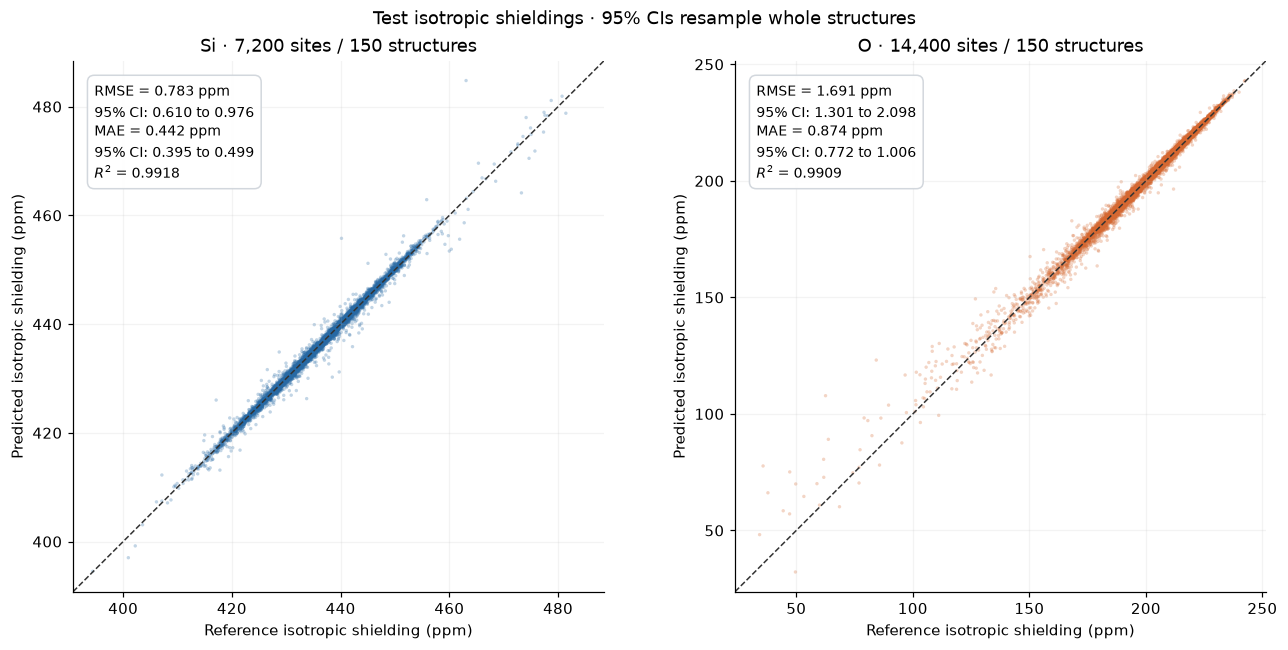

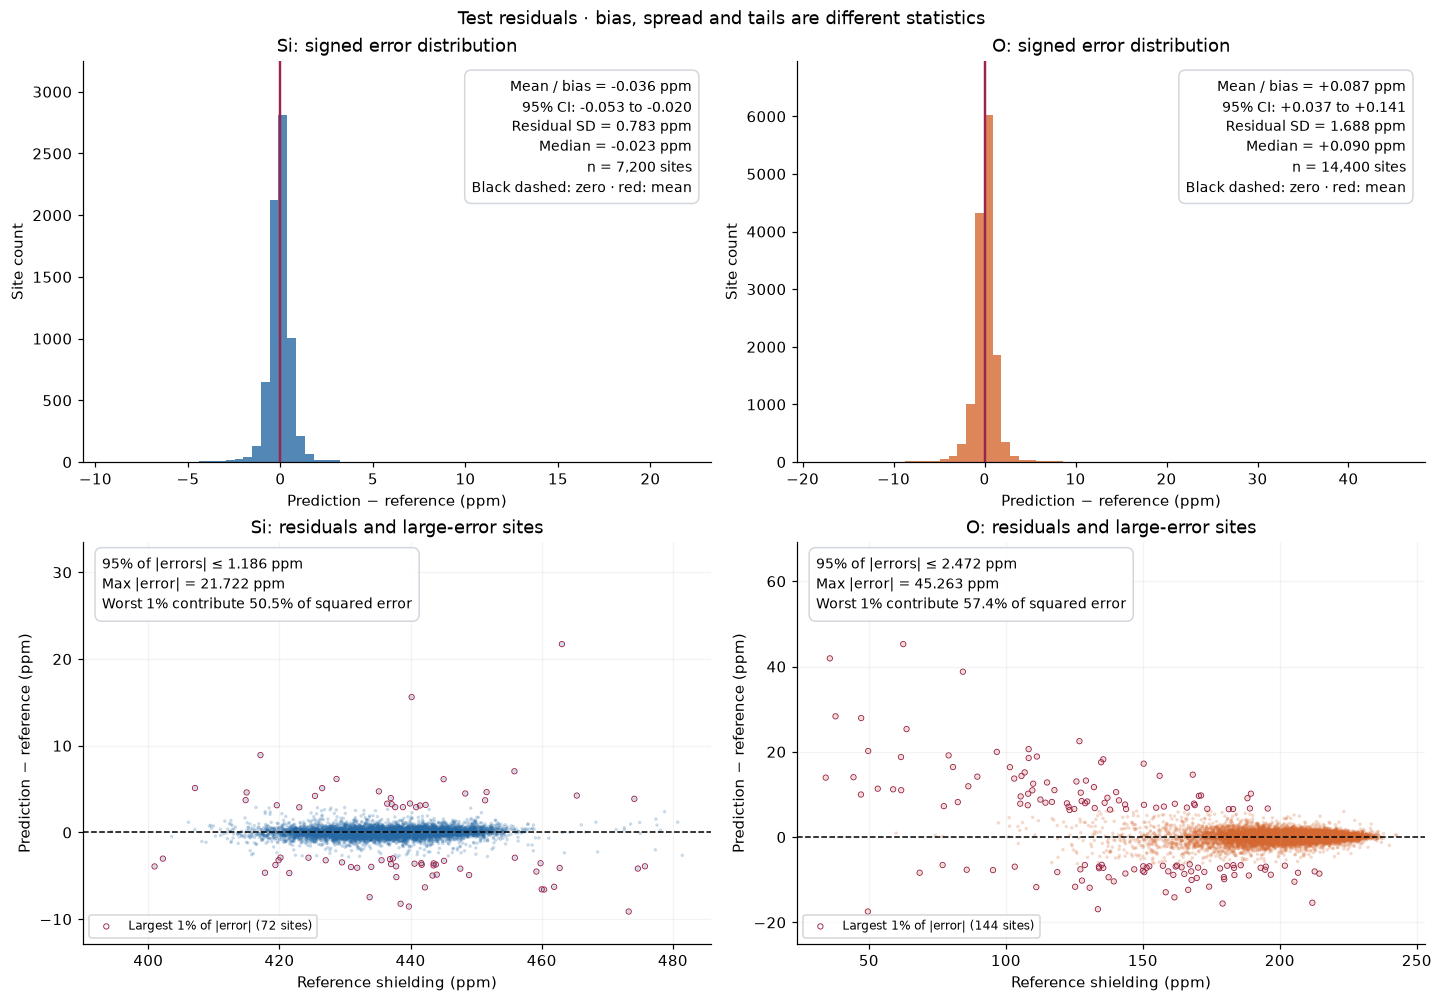

In [7]:
fig_parity, axes = plt.subplots(1, 2, figsize=(12, 5.8), layout='constrained')
for ax, element in zip(axes, ELEMENTS):
    group = test_sites[test_sites['element'].eq(element)]
    ref, pred = group['reference_ppm'].to_numpy(), group['prediction_ppm'].to_numpy()
    low, high = min(ref.min(), pred.min()), max(ref.max(), pred.max())
    margin = max(0.04 * (high - low), 0.1)
    limits = [low - margin, high + margin]
    ax.scatter(ref, pred, s=5, alpha=0.28, color=COLOURS[element], edgecolors='none', rasterized=True)
    ax.plot(limits, limits, '--', color='#333333', lw=1)
    ax.set(xlim=limits, ylim=limits, xlabel='Reference isotropic shielding (ppm)',
           ylabel='Predicted isotropic shielding (ppm)', title=f'{element} · {len(group):,} sites / {group.structure_index.nunique()} structures')
    ax.set_aspect('equal', adjustable='box')
    m = metrics.loc[('test', element)]
    stats_box(ax, f'RMSE = {m.RMSE_ppm:.3f} ppm\n95% CI: {ci_text(element, "RMSE_ppm")}\n'
                 f'MAE = {m.MAE_ppm:.3f} ppm\n95% CI: {ci_text(element, "MAE_ppm")}\n'
                 f'$R^2$ = {m.R2:.4f}', x=0.04, ha='left')
    ax.grid(alpha=0.15)
fig_parity.suptitle('Test isotropic shieldings · 95% CIs resample whole structures')
plt.show()

fig_residuals, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for column, element in enumerate(ELEMENTS):
    group = test_sites[test_sites['element'].eq(element)]
    error = group['error_ppm'].to_numpy()
    m = metrics.loc[('test', element)]
    ax = axes[0, column]
    ax.hist(error, bins=65, color=COLOURS[element], alpha=0.8)
    ax.axvline(0, color='black', linestyle='--', lw=1)
    ax.axvline(m.bias_ppm, color='#9a244b', lw=1.6)
    stats_box(ax, f'Mean / bias = {m.bias_ppm:+.3f} ppm\n'
                 f'95% CI: {ci_text(element, "bias_ppm", signed=True)}\n'
                 f'Residual SD = {error.std(ddof=0):.3f} ppm\n'
                 f'Median = {np.median(error):+.3f} ppm\n'
                 f'n = {len(error):,} sites\nBlack dashed: zero · red: mean', fontsize=9)
    ax.set(title=f'{element}: signed error distribution', xlabel='Prediction − reference (ppm)', ylabel='Site count')
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)

    ax = axes[1, column]
    tail_count = int(np.ceil(0.01 * len(error)))
    tail_positions = np.argsort(np.abs(error))[-tail_count:]
    tail_fraction = np.sum(error[tail_positions] ** 2) / np.sum(error ** 2)
    ax.scatter(group['reference_ppm'], error, s=5, alpha=0.25,
               color=COLOURS[element], edgecolors='none', rasterized=True)
    ax.scatter(group['reference_ppm'].to_numpy()[tail_positions], error[tail_positions], s=12,
               facecolors='none', edgecolors='#9a244b', linewidths=0.6,
               label=f'Largest 1% of |error| ({tail_count} sites)', rasterized=True)
    ax.axhline(0, color='black', linestyle='--', lw=1)
    stats_box(ax, f'95% of |errors| ≤ {m.p95_AE_ppm:.3f} ppm\n'
                 f'Max |error| = {m.max_AE_ppm:.3f} ppm\n'
                 f'Worst 1% contribute {100 * tail_fraction:.1f}% of squared error',
              x=0.03, y=0.97, ha='left', fontsize=9)
    ax.set(title=f'{element}: residuals and large-error sites', xlabel='Reference shielding (ppm)',
           ylabel='Prediction − reference (ppm)')
    lo, hi = error.min(), error.max()
    ax.set_ylim(lo - 0.12 * (hi - lo), hi + 0.38 * (hi - lo))
    ax.legend(loc='lower left', fontsize=8)
    ax.grid(alpha=0.15)
fig_residuals.suptitle('Test residuals · bias, spread and tails are different statistics')
plt.show()


## 7. Generalisation gap and coverage

Compare the **same best checkpoint** on all splits. Numbers above bars are point estimates; whiskers are 95% structure-bootstrap confidence intervals on **test metrics only**. The test/train RMSE ratio is descriptive, not a significance test. Training and validation bars have no uncertainty estimates here.

Reference-distribution labels give the mean and standard deviation of shielding in each split, in ppm. Legend counts are structures. The reported out-of-range count checks only the observed shielding range, not whether a geometry is structurally novel.


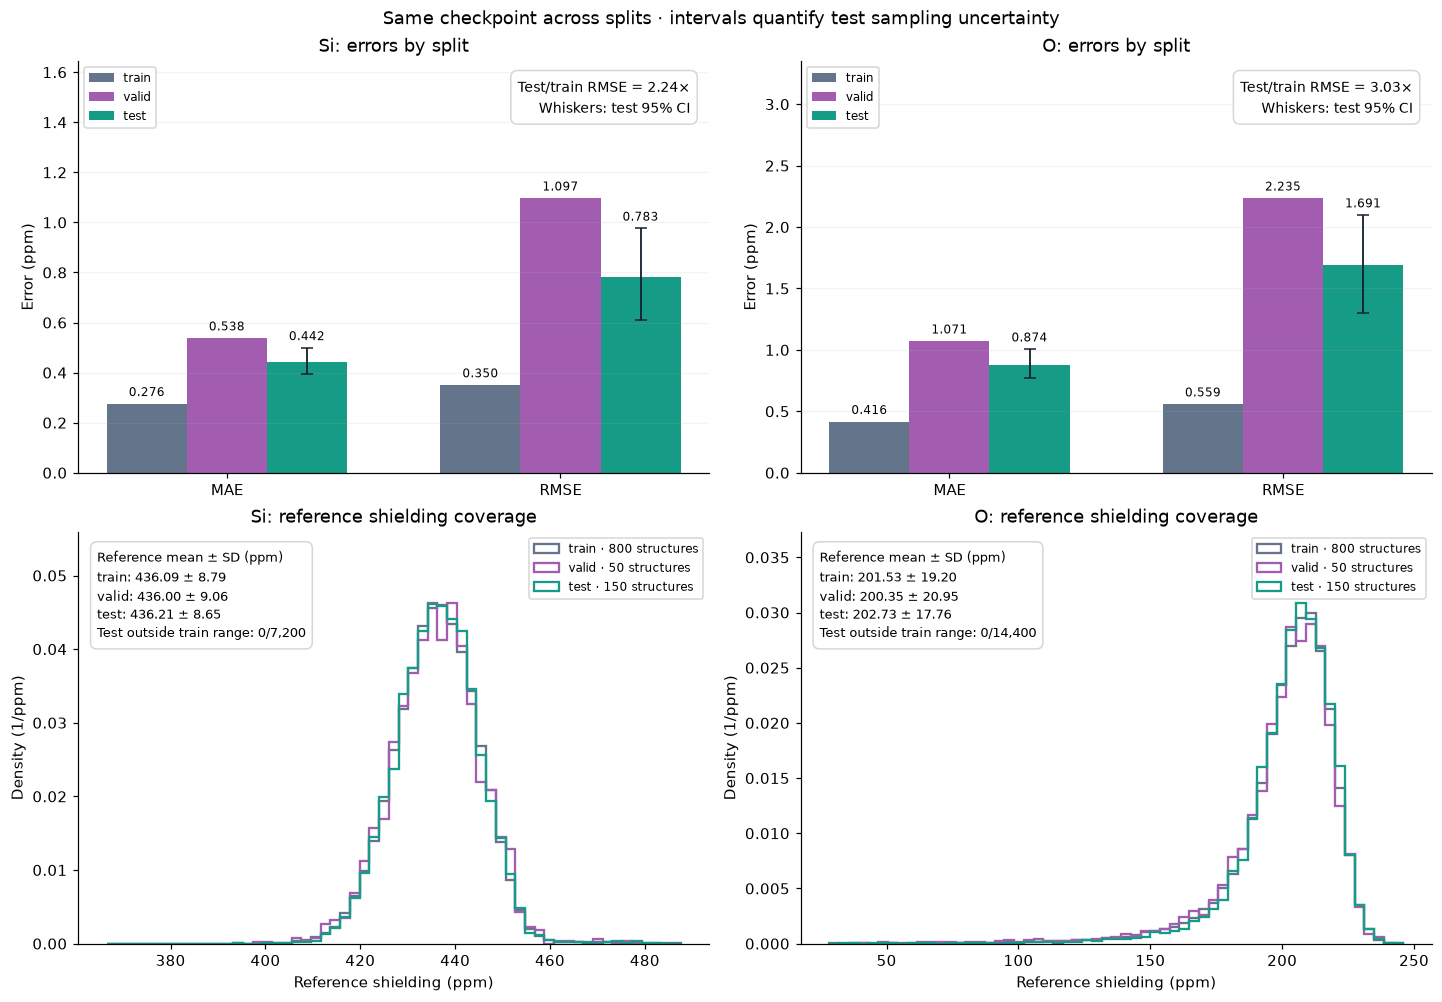

,train_min_ppm,train_max_ppm,test_min_ppm,test_max_ppm,test_sites_outside_training_range
element,,,,,
Si,366.547,487.530,394.405,481.430,0
O,28.290,245.859,34.254,242.538,0


In [8]:
fig_splits, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
split_colours = {'train': '#64748b', 'valid': '#a35db0', 'test': '#169b86'}
for column, element in enumerate(ELEMENTS):
    ax = axes[0, column]
    x = np.arange(2)
    max_top = 0.0
    for j, split in enumerate(SPLITS):
        m = metrics.loc[(split, element)]
        values = np.array([m.MAE_ppm, m.RMSE_ppm])
        positions = x + (j - 1) * 0.24
        bars = ax.bar(positions, values, width=0.24, color=split_colours[split], label=split)
        tops = values.copy()
        if split == 'test':
            cis = intervals.loc[element].loc[['MAE_ppm', 'RMSE_ppm']]
            low, high = cis['lower_95_ppm'].to_numpy(), cis['upper_95_ppm'].to_numpy()
            ax.errorbar(positions, values, yerr=np.vstack([values-low, high-values]),
                        fmt='none', ecolor='#17212f', capsize=4, lw=1.2, zorder=5)
            tops = high
        for pos, value, top in zip(positions, values, tops):
            ax.annotate(f'{value:.3f}', xy=(pos, top), xytext=(0, 5),
                        textcoords='offset points', ha='center', fontsize=8)
        max_top = max(max_top, tops.max())
    ratio = metrics.loc[('test', element), 'RMSE_ppm'] / metrics.loc[('train', element), 'RMSE_ppm']
    stats_box(ax, f'Test/train RMSE = {ratio:.2f}×\nWhiskers: test 95% CI', fontsize=9)
    ax.set_xticks(x, ['MAE', 'RMSE'])
    ax.set(title=f'{element}: errors by split', ylabel='Error (ppm)', ylim=(0, max_top * 1.50))
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=0.15)

    ax = axes[1, column]
    all_values = sites[sites['element'].eq(element)]['reference_ppm']
    bins = np.linspace(all_values.min(), all_values.max(), 60)
    text = ['Reference mean ± SD (ppm)']
    for split in SPLITS:
        group = sites[sites['element'].eq(element) & sites['split'].eq(split)]
        values = group['reference_ppm'].to_numpy()
        ax.hist(values, bins=bins, density=True, histtype='step', lw=1.5,
                color=split_colours[split], label=f'{split} · {group.structure_index.nunique()} structures')
        text.append(f'{split}: {values.mean():.2f} ± {values.std(ddof=0):.2f}')
    train = sites[sites['element'].eq(element) & sites['split'].eq('train')]['reference_ppm']
    test = test_sites[test_sites['element'].eq(element)]['reference_ppm']
    outside = int(((test < train.min()) | (test > train.max())).sum())
    text.append(f'Test outside train range: {outside}/{len(test):,}')
    stats_box(ax, '\n'.join(text), x=0.03, ha='left', fontsize=8.5)
    ax.set(title=f'{element}: reference shielding coverage', xlabel='Reference shielding (ppm)', ylabel='Density (1/ppm)')
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
    ax.legend(loc='upper right', fontsize=8)
fig_splits.suptitle('Same checkpoint across splits · intervals quantify test sampling uncertainty')
plt.show()

coverage_rows = []
for element in ELEMENTS:
    train = sites[sites['split'].eq('train') & sites['element'].eq(element)]['reference_ppm']
    test = sites[sites['split'].eq('test') & sites['element'].eq(element)]['reference_ppm']
    coverage_rows.append({'element': element, 'train_min_ppm': train.min(), 'train_max_ppm': train.max(),
                          'test_min_ppm': test.min(), 'test_max_ppm': test.max(),
                          'test_sites_outside_training_range': int(((test < train.min()) | (test > train.max())).sum())})
display(pd.DataFrame(coverage_rows).set_index('element').round(3))


## 8. Structure-level variation and largest errors

Each point is one structure's RMSE. The dashed line gives RMSE across all test sites; the shaded band is its 95% structure-bootstrap confidence interval. **The band is not a prediction interval for individual structures**: points outside it are not a test of statistical significance. Labels show the median and largest structure RMSE and identify the worst structure.

Overall site RMSE is computed from all squared site errors, not by averaging structure RMSEs. The table retains original structure/atom indices. No outliers are removed.


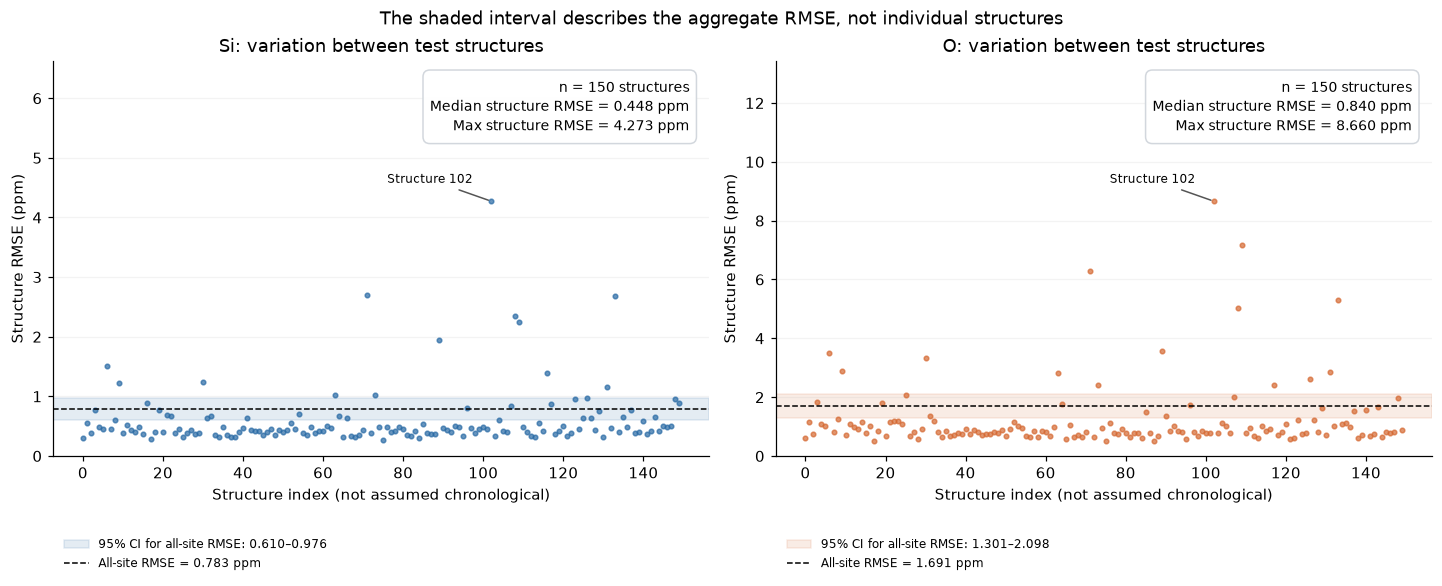

,element,structure_index,atom_index,reference_ppm,prediction_ppm,error_ppm
137201,Si,102,113,463.0756,484.7971,21.7216
141674,Si,133,122,440.1601,455.7758,15.6157
139226,Si,116,122,473.2606,464.1368,-9.1237
138051,Si,108,99,417.1068,426.0290,8.9222
137198,Si,102,110,439.7430,431.2000,-8.5430
138138,O,109,42,62.5485,107.8119,45.2633
137141,O,102,53,35.7518,77.6706,41.9188
141642,O,133,90,84.3146,123.1073,38.7927
137123,O,102,35,37.8288,66.1576,28.3289
138161,O,109,65,47.1874,75.1108,27.9233


In [9]:
structure_rows = []
for (element, structure_index), group in test_sites.groupby(['element', 'structure_index']):
    structure_rows.append({'element': element, 'structure_index': int(structure_index), 'sites': len(group),
                           **score(group['reference_ppm'], group['prediction_ppm'])})
structure_metrics = pd.DataFrame(structure_rows)
fig_structures, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout='constrained')
for ax, element in zip(axes, ELEMENTS):
    group = structure_metrics[structure_metrics['element'].eq(element)]
    aggregate = metrics.loc[('test', element), 'RMSE_ppm']
    ci = intervals.loc[(element, 'RMSE_ppm')]
    worst = group.loc[group['RMSE_ppm'].idxmax()]
    ax.axhspan(ci.lower_95_ppm, ci.upper_95_ppm, color=COLOURS[element], alpha=0.12,
               label=f'95% CI for all-site RMSE: {ci.lower_95_ppm:.3f}–{ci.upper_95_ppm:.3f}')
    ax.plot(group['structure_index'], group['RMSE_ppm'], 'o', ms=3, alpha=0.7, color=COLOURS[element])
    ax.axhline(aggregate, color='black', ls='--', lw=1,
               label=f'All-site RMSE = {aggregate:.3f} ppm')
    stats_box(ax, f'n = {len(group)} structures\nMedian structure RMSE = {group.RMSE_ppm.median():.3f} ppm\n'
                 f'Max structure RMSE = {worst.RMSE_ppm:.3f} ppm', fontsize=9)
    dx = -12 if worst.structure_index > 75 else 12
    ax.annotate(f'Structure {int(worst.structure_index)}', (worst.structure_index, worst.RMSE_ppm),
                xytext=(dx, 12), textcoords='offset points', fontsize=8,
                ha='right' if dx < 0 else 'left', arrowprops={'arrowstyle':'-', 'color':'#555555'})
    ax.set(title=f'{element}: variation between test structures', xlabel='Structure index (not assumed chronological)',
           ylabel='Structure RMSE (ppm)', ylim=(0, worst.RMSE_ppm * 1.55))
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.18), fontsize=8, frameon=False)
    ax.grid(axis='y', alpha=0.15)
fig_structures.suptitle('The shaded interval describes the aggregate RMSE, not individual structures')
plt.show()
worst_sites = pd.concat([test_sites[test_sites['element'].eq(el)].nlargest(5, 'absolute_error_ppm') for el in ELEMENTS])
display(worst_sites[['element','structure_index','atom_index','reference_ppm','prediction_ppm','error_ppm']].round(4))


## 9. Does coordination explain the large errors?

Count oxygen neighbours around Si and silicon neighbours around O within **2.2 Å**, including periodic boundaries. The common groups are Si with four O neighbours and O with two Si neighbours. In this test set, the other groups contain Si with three/five neighbours and O with one/three neighbours.

The figure puts **site-level RMSE beside the number and percentage of sites** in each group. This separates the question “how frequent is this environment?” from “how accurate are its predictions?”. Whiskers are descriptive 95% confidence intervals from 2,000 whole-structure bootstrap resamples, retaining within-structure dependence. They assume independent structures and do not include training-seed uncertainty. Rare-group estimates have fewer supporting structures.

**Interpretation:** these are exploratory, distance-based groups, not definitive bonding assignments. A stretched bond near the cutoff can change the count. The association does not prove coordination itself causes the errors, and some normally coordinated sites also have large errors. All test sites remain included; no model fitting uses these labels. Edit `COORDINATION_CUTOFF` below to check threshold sensitivity.


In [10]:
from ase.neighborlist import neighbor_list

COORDINATION_CUTOFF = 2.2  # Å; provisional geometric criterion, not a universal bond definition.
coordination_rows = []
for structure_index, atoms in enumerate(structures['test']):
    centre, neighbour, distance = neighbor_list('ijd', atoms, COORDINATION_CUTOFF)
    unlike = (atoms.numbers[centre] != atoms.numbers[neighbour]) & (distance < COORDINATION_CUTOFF)
    counts = np.bincount(centre[unlike], minlength=len(atoms))
    coordination_rows.append(pd.DataFrame({
        'structure_index': structure_index, 'atom_index': np.arange(len(atoms)),
        'opposite_element_neighbours': counts,
    }))
coordination_sites = test_sites.merge(pd.concat(coordination_rows, ignore_index=True),
                                      on=['structure_index', 'atom_index'], validate='one_to_one')
assert len(coordination_sites) == len(test_sites)
coordination_sites['group'] = np.where(
    coordination_sites['opposite_element_neighbours'].eq(coordination_sites['element'].map({'Si': 4, 'O': 2})),
    'Common coordination', 'Other coordination')

# Resample full structures, including those with zero sites from a particular group.
coord_rng = np.random.default_rng(42)
n_structures = len(structures['test'])
coord_draws = coord_rng.integers(0, n_structures, size=(2000, n_structures))
coordination_results = []
for element in ELEMENTS:
    element_sites = coordination_sites[coordination_sites['element'].eq(element)]
    for name in ['Common coordination', 'Other coordination']:
        group = element_sites[element_sites['group'].eq(name)]
        assert len(group) > 0, f'No {element} sites in {name} at this cutoff.'
        by_structure = group.groupby('structure_index')['error_ppm'].agg(
            n='size', squared_error=lambda x: float(np.square(x).sum()))
        by_structure = by_structure.reindex(np.arange(n_structures), fill_value=0)
        sample_counts = by_structure['n'].to_numpy()[coord_draws].sum(axis=1)
        sample_sse = by_structure['squared_error'].to_numpy()[coord_draws].sum(axis=1)
        nonempty = sample_counts > 0
        bootstrap_rmse = np.sqrt(sample_sse[nonempty] / sample_counts[nonempty])
        low, high = np.quantile(bootstrap_rmse, [0.025, 0.975])
        coordination_results.append({
            'element': element, 'group': name,
            'observed_neighbour_counts': ', '.join(map(str, sorted(group.opposite_element_neighbours.unique()))),
            'sites': len(group), 'percent_of_element_sites': 100 * len(group) / len(element_sites),
            'structures_containing_group': group.structure_index.nunique(),
            **score(group.reference_ppm, group.prediction_ppm),
            'RMSE_CI_lower_ppm': low, 'RMSE_CI_upper_ppm': high,
            'nonempty_bootstrap_resamples': int(nonempty.sum()),
        })
coordination_metrics = pd.DataFrame(coordination_results).set_index(['element', 'group'])
print(f'Test-site coordination groups: unlike neighbours within {COORDINATION_CUTOFF:.1f} Å.')
display(coordination_metrics[['observed_neighbour_counts', 'sites', 'percent_of_element_sites',
                              'structures_containing_group', 'MAE_ppm', 'RMSE_ppm',
                              'RMSE_CI_lower_ppm', 'RMSE_CI_upper_ppm']].round(3))

# Keep the exact coordination categories visible rather than hiding them in the pooled groups.
coordination_detail = pd.DataFrame([
    {'element': element, 'neighbours': int(count), 'sites': len(group),
     'structures': group.structure_index.nunique(),
     'MAE_ppm': group.absolute_error_ppm.mean(),
     'RMSE_ppm': np.sqrt(np.mean(group.error_ppm ** 2))}
    for (element, count), group in coordination_sites.groupby(['element', 'opposite_element_neighbours'])
]).set_index(['element', 'neighbours'])


Test-site coordination groups: unlike neighbours within 2.2 Å.


observed_neighbour_counts  sites  percent_of_element_sites  structures_containing_group  MAE_ppm  RMSE_ppm  RMSE_CI_lower_ppm  \
element group                                                                                                                                               
Si      Common coordination                         4   7164                    99.500                          150    0.427     0.693              0.574   
        Other coordination                       3, 5     36                     0.500                           26    3.444     5.226              2.826   
O       Common coordination                         2  14302                    99.319                          150    0.844     1.542              1.187   
        Other coordination                       1, 3     98                     0.681                           51    5.287     8.553              5.658   

                             RMSE_CI_upper_ppm  
element group                                   
Si      Common coordination              0.819  
        Other coordination               7.633  
O       Common coordination              1.930  
        Other coordination              11.397

Exact coordination categories (small groups require caution):


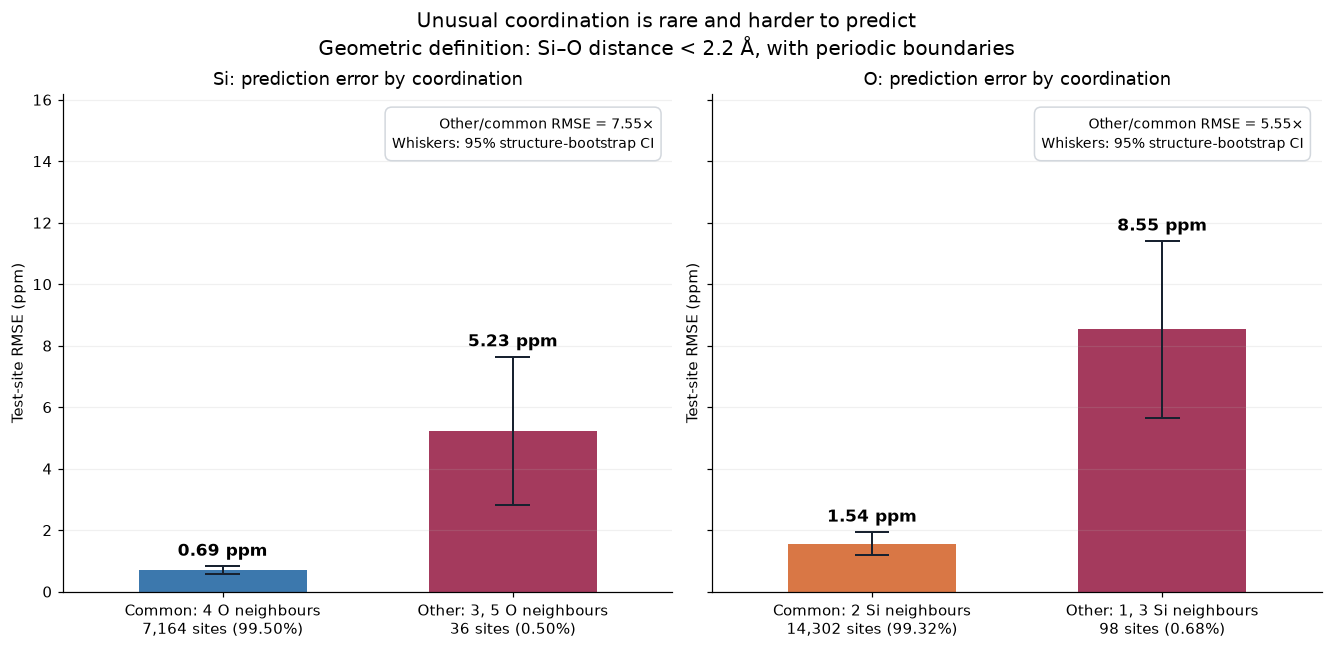

sites  structures  MAE_ppm  RMSE_ppm
element neighbours                                      
O       1              34          29    9.253    12.649
        2           14302         150    0.844     1.542
        3              64          50    3.180     5.196
Si      3               3           3    4.267     5.396
        4            7164         150    0.427     0.693
        5              33          24    3.369     5.210

In [11]:
fig_coordination, axes = plt.subplots(1, 2, figsize=(12, 5.8), sharey=True, layout='constrained')
max_interval = coordination_metrics.RMSE_CI_upper_ppm.max()
for ax, element in zip(axes, ELEMENTS):
    table = coordination_metrics.loc[element].loc[['Common coordination', 'Other coordination']]
    values = table.RMSE_ppm.to_numpy()
    low, high = table.RMSE_CI_lower_ppm.to_numpy(), table.RMSE_CI_upper_ppm.to_numpy()
    positions = np.arange(2)
    ax.bar(positions, values, width=0.58, color=[COLOURS[element], '#9a244b'], alpha=0.9)
    # Draw percentile interval bounds directly (no assumption that they contain the point estimate).
    ax.vlines(positions, low, high, color='#17212f', linewidth=1.3)
    ax.hlines(low, positions-0.06, positions+0.06, color='#17212f', linewidth=1.3)
    ax.hlines(high, positions-0.06, positions+0.06, color='#17212f', linewidth=1.3)
    for x, value, upper in zip(positions, values, high):
        ax.annotate(f'{value:.2f} ppm', (x, max(value, upper)), xytext=(0, 7),
                    textcoords='offset points', ha='center', fontsize=11, fontweight='bold')
    neighbour = 'O' if element == 'Si' else 'Si'
    tick_labels = []
    for (_, row), kind in zip(table.iterrows(), ['Common', 'Other']):
        tick_labels.append(f'{kind}: {row.observed_neighbour_counts} {neighbour} neighbours\n'
                           f'{int(row.sites):,} sites ({row.percent_of_element_sites:.2f}%)')
    ax.set_xticks(positions, tick_labels, fontsize=10)
    ratio = values[1] / values[0]
    stats_box(ax, f'Other/common RMSE = {ratio:.2f}×\nWhiskers: 95% structure-bootstrap CI', fontsize=9)
    ax.set(title=f'{element}: prediction error by coordination', ylabel='Test-site RMSE (ppm)',
           ylim=(0, max_interval * 1.42), xlim=(-0.55, 1.55))
    ax.grid(axis='y', alpha=0.18)
fig_coordination.suptitle(f'Unusual coordination is rare and harder to predict\n'
                         f'Geometric definition: Si–O distance < {COORDINATION_CUTOFF:.1f} Å, with periodic boundaries',
                         fontsize=13)
plt.show()
print('Exact coordination categories (small groups require caution):')
display(coordination_detail.round(3))


## 10. Results and reproducibility record

These results quantify reproduction of the supplied **DFT isotropic shielding labels**. With a fixed reference and unit-magnitude sign conversion, shielding MAE/RMSE are unchanged when expressed as chemical-shift errors. A fitted slope would change their scale. No experimental referencing is estimated here.

Direct claims of superiority to published models would require the same nuclei, reference calculation settings, structural domain and test split. The large Si/O baseline separation is why per-element results, rather than pooled correlation, are the headline.


In [12]:
lines = [f'**Best checkpoint: epoch {best_epoch} of {last_epoch}.** ',
         f"Test evaluation: {len(structures['test'])} structures and {len(test_sites):,} atomic sites.", '']
for element in ELEMENTS:
    m = metrics.loc[('test', element)]
    interval = intervals.loc[(element, 'RMSE_ppm')]
    gap = m.RMSE_ppm / metrics.loc[('train', element), 'RMSE_ppm']
    lines.append(f"- **{element}:** MAE **{m.MAE_ppm:.3f} ppm**, RMSE **{m.RMSE_ppm:.3f} ppm**, "
                 f"bias {m.bias_ppm:+.3f} ppm, $R^2={m.R2:.4f}$. "
                 f"Structure-bootstrap RMSE interval: {interval.lower_95_ppm:.3f}–{interval.upper_95_ppm:.3f} ppm. "
                 f"RMSE is {m.RMSE_reduction_vs_baseline_pct:.1f}% below the elemental-mean baseline "
                 f"and {gap:.2f}× the training RMSE.")
lines += ['', 'The test set is used for evaluation only; no correction or model selection is fitted to it. '
          'Further tuning informed by these test results would require a new independent test set for an unbiased final assessment.']
display(Markdown('\n'.join(lines)))

manifest = {
    'evaluation_utc': datetime.now(timezone.utc).isoformat(),
    'run': RUN_NAME, 'best_epoch_1based': best_epoch, 'last_epoch_1based': last_epoch,
    'target': 'MS_Iso_QM = trace(ms)/3; absolute isotropic shielding', 'units': 'ppm',
    'error_sign': 'prediction minus reference', 'reference': 'CASTEP/PBE labels in supplied XYZ files',
    'model_sha256': model_hash, 'best_checkpoint_sha256': sha256(RUN / 'checkpoints/best.ckpt'),
    'config_sha256': sha256(RUN / 'train-config.yaml'),
    'helper_sha256': sha256(PROJECT / 'nmr_helpers/extract_ms_isotropy.py'),
    'data_sha256': data_hashes, 'versions': versions, 'python': platform.python_version(),
    'device': 'cpu', 'dtype': 'float32 predictions; float64 metrics', 'torch_threads': THREADS,
    'site_counts': audit['sites'].to_dict(), 'structure_counts': audit['structures'].to_dict(),
    'bootstrap': {'unit': 'structure', 'resamples': 2000, 'seed': 42,
                  'limitation': 'Assumes independent structures; trajectory dependence not assessed.'},
    'coordination_diagnostic': {'cutoff_A': COORDINATION_CUTOFF, 'periodic': True,
        'groups': 'Si: 4 versus other O neighbours; O: 2 versus other Si neighbours',
        'split': 'test', 'bootstrap_resamples': 2000, 'seed': 42},
    'corrections_applied': False, 'outliers_removed': False,
}
print(json.dumps(manifest, indent=2))
print('Tables remain available as metrics, sites, structure_metrics, intervals and audit.')


{
  "evaluation_utc": "2026-10-13T13:46:18.671243+00:00",
  "run": "TensorNequIP-NMR-9065266",
  "best_epoch_1based": 188,
  "last_epoch_1based": 300,
  "target": "MS_Iso_QM = trace(ms)/3; absolute isotropic shielding",
  "units": "ppm",
  "error_sign": "prediction minus reference",
  "reference": "CASTEP/PBE labels in supplied XYZ files",
  "model_sha256": "f2159b2fe9bd80147c46b55413c233cd616d825c976e75bf80de345f4104b32a",
  "best_checkpoint_sha256": "4d93d7073e527b408e9450efbb289901e87670b2bfd9d2b183cdcb1bf31e490c",
  "config_sha256": "7e510894939e38f50da45b5fb23dadcf0932b70a627f3661bda73e15d798a209",
  "helper_sha256": "4847dab4b6cbf7375eecdad2fe8aa68dc9b919b3e993e96d27f03c976c53a3cc",
  "data_sha256": {
    "train": "77de1ed9983781e906c35aa63d4f134a0777c6e38a933791c6db866f8b9c6fda",
    "valid": "e73ce6065ce6729d6549d5b30a4129634aaec84e3a2429c044d31d81020a4d11",
    "test": "64aa8e6166ef09f25118ab8d3b487fa2fc7be17ce124bf5981111fa89a4313d9"
  },
  "versions": {
    "graph-pes": "1.0

**Best checkpoint: epoch 188 of 300.** 
Test evaluation: 150 structures and 21,600 atomic sites.

- **Si:** MAE **0.442 ppm**, RMSE **0.783 ppm**, bias -0.036 ppm, $R^2=0.9918$. Structure-bootstrap RMSE interval: 0.610–0.976 ppm. RMSE is 90.9% below the elemental-mean baseline and 2.24× the training RMSE.
- **O:** MAE **0.874 ppm**, RMSE **1.691 ppm**, bias +0.087 ppm, $R^2=0.9909$. Structure-bootstrap RMSE interval: 1.301–2.098 ppm. RMSE is 90.5% below the elemental-mean baseline and 3.03× the training RMSE.

The test set is used for evaluation only; no correction or model selection is fitted to it. Further tuning informed by these test results would require a new independent test set for an unbiased final assessment.